<a href="https://colab.research.google.com/github/bharath-chandra-2719/E-Waste-Collection-Demand-Forecasting-and-Zone-Optimization-Using-R/blob/main/E_Waste_Forecsting_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## **E-Waste Collection Demand Forecasting and Zone Optimization Using R**

CELL 1 — Install required packages

In [1]:
# Install required R packages

install.packages(c(
  "readr",
  "readxl",
  "dplyr",
  "tidyr",
  "ggplot2",
  "forecast",
  "randomForest",
  "cluster",
  "scales"
), repos = "https://cloud.r-project.org")

Installing packages into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

also installing the dependencies ‘colorspace’, ‘fracdiff’, ‘lmtest’, ‘timeDate’, ‘urca’, ‘zoo’, ‘RcppArmadillo’




CELL 2 — Load libraries

In [2]:
library(readr)
library(readxl)
library(dplyr)
library(tidyr)
library(ggplot2)
library(forecast)
library(randomForest)
library(cluster)
library(scales)

cat("All libraries loaded successfully!\n")


Attaching package: ‘dplyr’


The following objects are masked from ‘package:stats’:

    filter, lag


The following objects are masked from ‘package:base’:

    intersect, setdiff, setequal, union


randomForest 4.7-1.2

Type rfNews() to see new features/changes/bug fixes.


Attaching package: ‘randomForest’


The following object is masked from ‘package:ggplot2’:

    margin


The following object is masked from ‘package:dplyr’:

    combine



Attaching package: ‘scales’


The following object is masked from ‘package:readr’:

    col_factor




All libraries loaded successfully!


CELL 3 — Check uploaded files

In [3]:
# Show files uploaded to Colab

list.files("/content")

cat("\nRequired files should be visible above.\n")

[1] "DDW_PCA2805_2011_MDDS with UI.xlsx" "RS_Session_269_AU_525_1.csv"       
[3] "RS_Session_269_AU_525_A.csv"        "RS_Session_270_AS_140_A_i.csv"     
[5] "sample_data"


Required files should be visible above.


CELL 4 — Create project folders

In [4]:
# Create folders for outputs

dir.create("/content/EWaste_Case_Study", showWarnings = FALSE)
dir.create("/content/EWaste_Case_Study/outputs", showWarnings = FALSE)
dir.create("/content/EWaste_Case_Study/data", showWarnings = FALSE)

cat("Project folders created.\n")

Project folders created.


CELL 5 — Load main e-waste dataset

In [5]:
# ============================================================
# MAIN E-WASTE DATA
# ============================================================

ewaste_data <- read_csv(
  "/content/RS_Session_269_AU_525_A.csv",
  show_col_types = FALSE
)

# Display column names
print(names(ewaste_data))

# Display data
print(ewaste_data)

[1] "Financial Year (FY)"                 
[2] "E-Waste Generation - Metric Ton (MT)"
[3] "E-Waste Recycled (MT)"               
# A tibble: 5 × 3
  `Financial Year (FY)` E-Waste Generation - Metric Ton…¹ E-Waste Recycled (MT…²
  <chr>                                             <dbl>                  <dbl>
1 2020-21                                        1346496.                354541.
2 2021-22                                        1601155.                527132.
3 2022-23                                        1609117                 539256 
4 2023-24                                        1254287.                778205.
5 2024-25                                        1397956.               1159228.
# ℹ abbreviated names: ¹​`E-Waste Generation - Metric Ton (MT)`,
#   ²​`E-Waste Recycled (MT)`


CELL 6 — Clean main e-waste dataset

In [6]:
# ============================================================
# CLEAN MAIN E-WASTE DATA
# ============================================================

ewaste_clean <- ewaste_data

# Rename columns according to their position
# This avoids problems caused by different CSV column names

names(ewaste_clean)[1:3] <- c(
  "Year",
  "Generated",
  "Recycled"
)

# Convert to numeric
ewaste_clean$Generated <- as.numeric(ewaste_clean$Generated)
ewaste_clean$Recycled <- as.numeric(ewaste_clean$Recycled)

# Remove missing generation values
ewaste_clean <- ewaste_clean %>%
  filter(!is.na(Generated))

# Display cleaned dataset
print(ewaste_clean)

# Check dimensions
cat("\nRows:", nrow(ewaste_clean), "\n")
cat("Columns:", ncol(ewaste_clean), "\n")

# A tibble: 5 × 3
  Year    Generated Recycled
  <chr>       <dbl>    <dbl>
1 2020-21  1346496.  354541.
2 2021-22  1601155.  527132.
3 2022-23  1609117   539256 
4 2023-24  1254287.  778205.
5 2024-25  1397956. 1159228.

Rows: 5 
Columns: 3 


CELL 7 — E-waste generation vs recycling plot

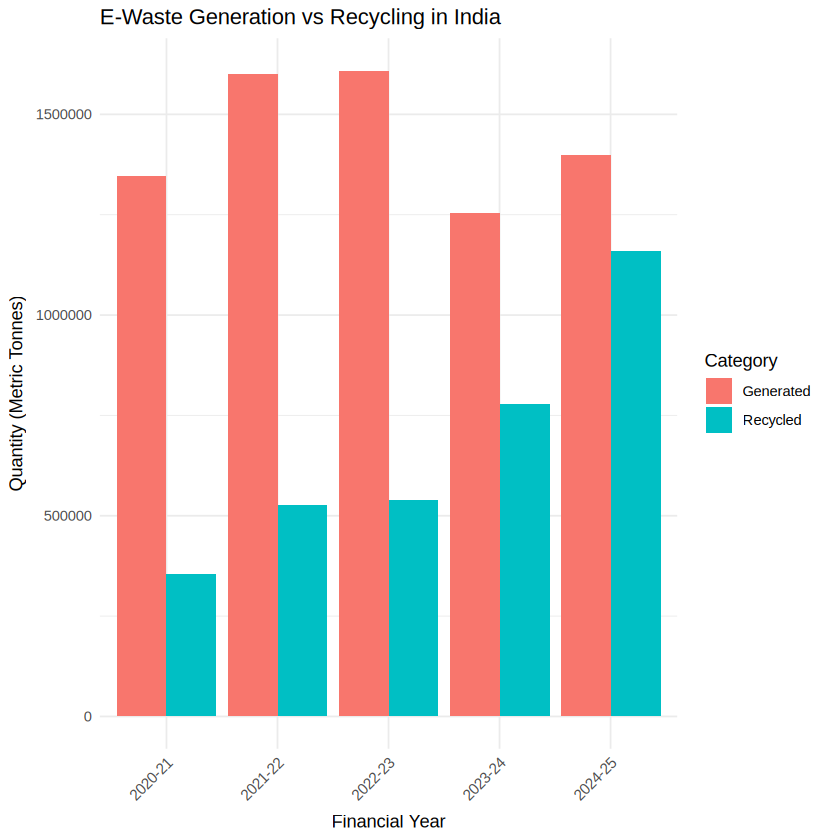

In [7]:
# ============================================================
# PLOT 1: GENERATION VS RECYCLING
# ============================================================

ewaste_long <- ewaste_clean %>%
  pivot_longer(
    cols = c(Generated, Recycled),
    names_to = "Category",
    values_to = "Quantity"
  )

p1 <- ggplot(
  ewaste_long,
  aes(x = Year, y = Quantity, fill = Category)
) +
  geom_col(position = "dodge") +
  labs(
    title = "E-Waste Generation vs Recycling in India",
    x = "Financial Year",
    y = "Quantity (Metric Tonnes)",
    fill = "Category"
  ) +
  theme_minimal() +
  theme(
    axis.text.x = element_text(
      angle = 45,
      hjust = 1
    )
  )

print(p1)

ggsave(
  "/content/EWaste_Case_Study/outputs/01_ewaste_generation_vs_recycling.png",
  p1,
  width = 9,
  height = 6,
  dpi = 300
)

CELL 8 — Recycling percentage

In [8]:
# ============================================================
# RECYCLING PERCENTAGE
# ============================================================

ewaste_percentage <- ewaste_clean %>%
  mutate(
    Recycling_Percentage =
      (Recycled / Generated) * 100
  )

print(
  ewaste_percentage %>%
    select(
      Year,
      Generated,
      Recycled,
      Recycling_Percentage
    )
)

# A tibble: 5 × 4
  Year    Generated Recycled Recycling_Percentage
  <chr>       <dbl>    <dbl>                <dbl>
1 2020-21  1346496.  354541.                 26.3
2 2021-22  1601155.  527132.                 32.9
3 2022-23  1609117   539256                  33.5
4 2023-24  1254287.  778205.                 62.0
5 2024-25  1397956. 1159228.                 82.9


CELL 9 — Recycling percentage plot

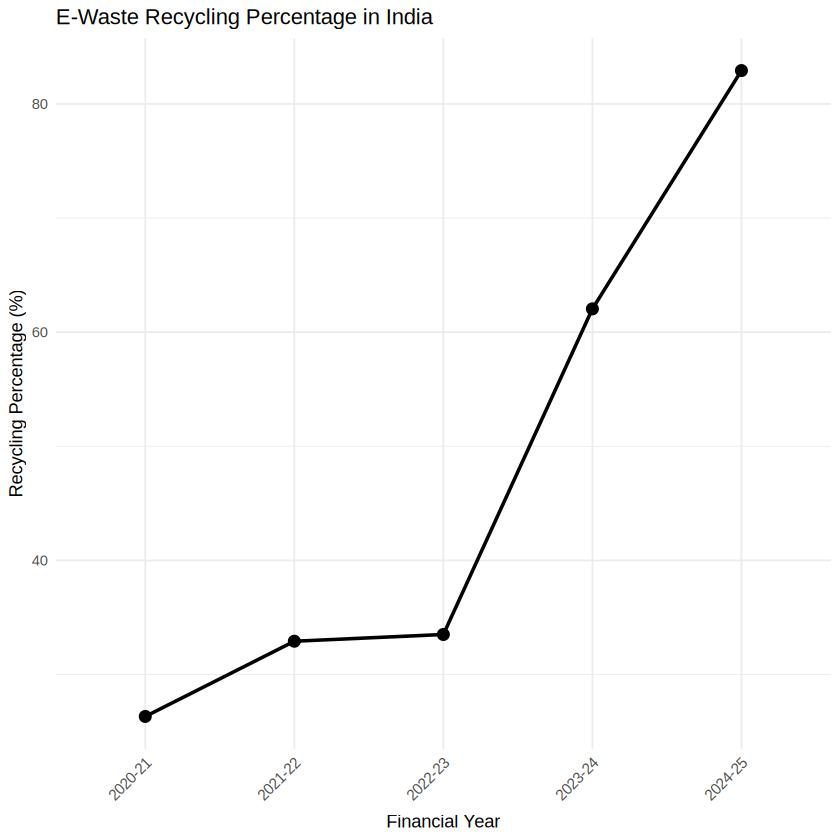

In [10]:
# ============================================================
# PLOT 2: RECYCLING PERCENTAGE
# ============================================================

p2 <- ggplot(
  ewaste_percentage,
  aes(
    x = Year,
    y = Recycling_Percentage,
    group = 1
  )
) +
  geom_line(linewidth = 1) +
  geom_point(size = 3) +
  labs(
    title = "E-Waste Recycling Percentage in India",
    x = "Financial Year",
    y = "Recycling Percentage (%)"
  ) +
  theme_minimal() +
  theme(
    axis.text.x = element_text(
      angle = 45,
      hjust = 1
    )
  )

print(p2)

ggsave(
  "/content/EWaste_Case_Study/outputs/02_ewaste_recycling_percentage.png",
  p2,
  width = 10,
  height = 6,
  dpi = 300
)

CELL 10 — Annual e-waste trend

# A tibble: 5 × 4
  Year    Generated Recycled Year_Num
  <chr>       <dbl>    <dbl>    <dbl>
1 2020-21  1346496.  354541.     2020
2 2021-22  1601155.  527132.     2021
3 2022-23  1609117   539256      2022
4 2023-24  1254287.  778205.     2023
5 2024-25  1397956. 1159228.     2024


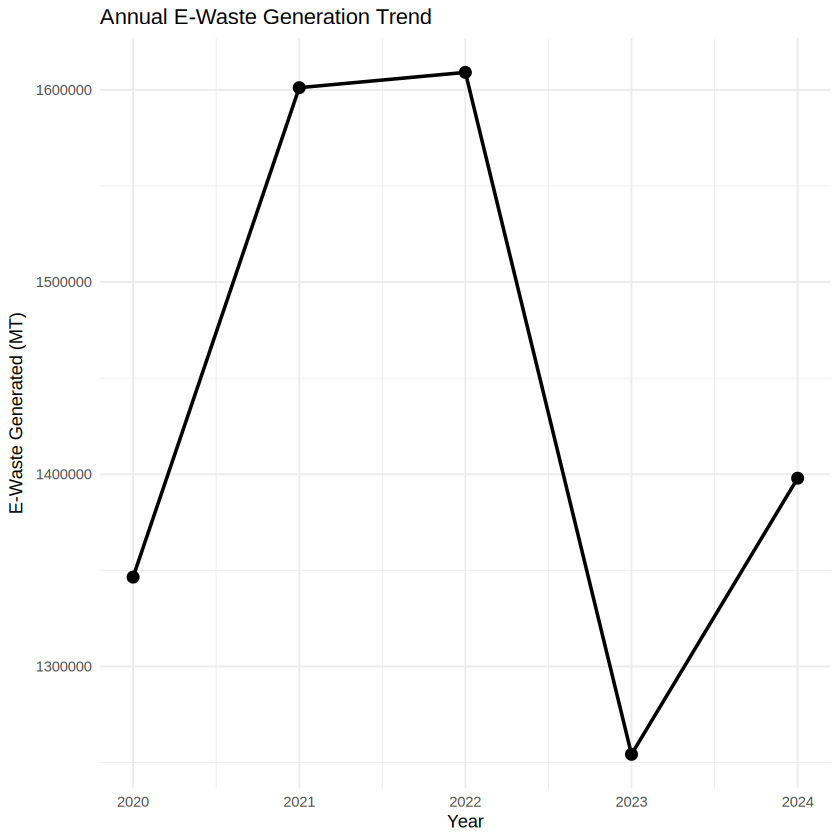

In [11]:
# ============================================================
# PLOT 3: ANNUAL E-WASTE TREND
# ============================================================

annual_data <- ewaste_clean %>%
  mutate(
    Year_Num = as.numeric(substr(
      as.character(Year),
      1,
      4
    ))
  ) %>%
  arrange(Year_Num)

print(annual_data)

p3 <- ggplot(
  annual_data,
  aes(
    x = Year_Num,
    y = Generated
  )
) +
  geom_line(linewidth = 1) +
  geom_point(size = 3) +
  labs(
    title = "Annual E-Waste Generation Trend",
    x = "Year",
    y = "E-Waste Generated (MT)"
  ) +
  theme_minimal()

print(p3)

ggsave(
  "/content/EWaste_Case_Study/outputs/03_annual_ewaste_trend.png",
  p3,
  width = 9,
  height = 6,
  dpi = 300
)

CELL 11 — Create time series

Time Series:
Start = 2020 
End = 2024 
Frequency = 1 
[1] 1346496 1601155 1609117 1254287 1397956


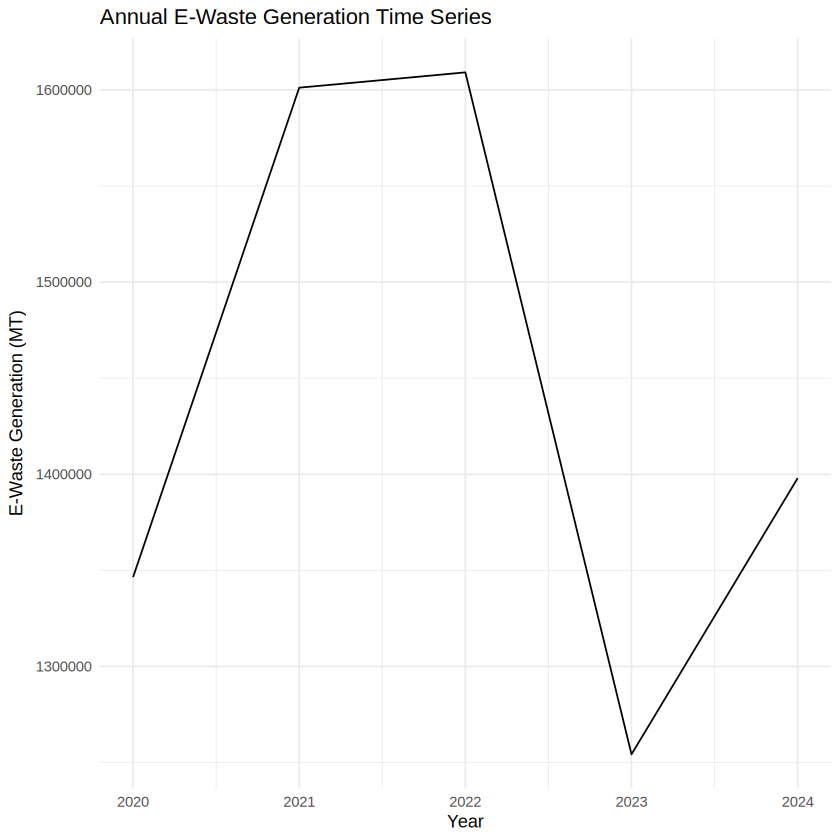

In [12]:
# ============================================================
# TIME SERIES
# ============================================================

ewaste_ts <- ts(
  annual_data$Generated,
  start = min(annual_data$Year_Num),
  frequency = 1
)

print(ewaste_ts)

# Basic time-series plot

p4 <- autoplot(ewaste_ts) +
  labs(
    title = "Annual E-Waste Generation Time Series",
    x = "Year",
    y = "E-Waste Generation (MT)"
  ) +
  theme_minimal()

print(p4)

ggsave(
  "/content/EWaste_Case_Study/outputs/04_ewaste_time_series.png",
  p4,
  width = 9,
  height = 6,
  dpi = 300
)

CELL 12 — ARIMA forecasting


ARIMA MODEL
Series: ewaste_ts 
ARIMA(0,0,0) with non-zero mean 

Coefficients:
           mean
      1441802.2
s.e.    63105.9

sigma^2 = 2.489e+10:  log likelihood = -66.38
AIC=136.76   AICc=142.76   BIC=135.98

ARIMA FORECAST
     Point Forecast   Lo 80   Hi 80   Lo 95   Hi 95
2025        1441802 1239622 1643982 1132594 1751010
2026        1441802 1239622 1643982 1132594 1751010


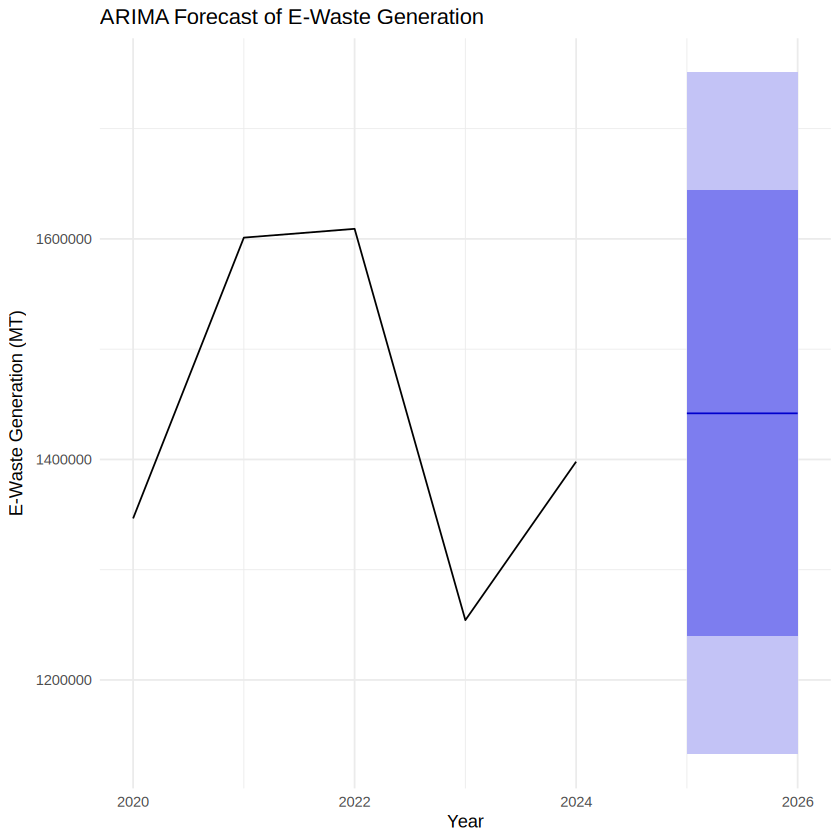

In [13]:
# ============================================================
# ARIMA FORECAST
# ============================================================

# Fit ARIMA model

arima_model <- auto.arima(
  ewaste_ts,
  seasonal = FALSE
)

cat("\n============================\n")
cat("ARIMA MODEL\n")
cat("============================\n")

print(arima_model)

# Forecast next 2 years

arima_forecast <- forecast(
  arima_model,
  h = 2
)

cat("\n============================\n")
cat("ARIMA FORECAST\n")
cat("============================\n")

print(arima_forecast)

# Plot forecast

p5 <- autoplot(arima_forecast) +
  labs(
    title = "ARIMA Forecast of E-Waste Generation",
    x = "Year",
    y = "E-Waste Generation (MT)"
  ) +
  theme_minimal()

print(p5)

ggsave(
  "/content/EWaste_Case_Study/outputs/05_arima_forecast.png",
  p5,
  width = 9,
  height = 6,
  dpi = 300
)

CELL 13 — Save ARIMA forecast values

In [14]:
# ============================================================
# SAVE ARIMA FORECAST VALUES
# ============================================================

forecast_values <- data.frame(
  Year = time(arima_forecast$mean),
  Forecast = as.numeric(arima_forecast$mean),
  Lower_80 = as.numeric(
    arima_forecast$lower[, "80%"]
  ),
  Upper_80 = as.numeric(
    arima_forecast$upper[, "80%"]
  )
)

print(forecast_values)

write.csv(
  forecast_values,
  "/content/EWaste_Case_Study/outputs/arima_forecast_values.csv",
  row.names = FALSE
)

  Year Forecast Lower_80 Upper_80
1 2025  1441802  1239622  1643982
2 2026  1441802  1239622  1643982


CELL 14 — Prepare Random Forest data

In [15]:
# ============================================================
# RANDOM FOREST DATA
# ============================================================

rf_data <- annual_data %>%
  select(
    Year_Num,
    Generated
  )

print(rf_data)

# A tibble: 5 × 2
  Year_Num Generated
     <dbl>     <dbl>
1     2020  1346496.
2     2021  1601155.
3     2022  1609117 
4     2023  1254287.
5     2024  1397956.


CELL 15 — Train/test split



In [16]:
# ============================================================
# TRAIN TEST SPLIT
# ============================================================

n <- nrow(rf_data)

train_data <- rf_data[
  1:(n - 2),
]

test_data <- rf_data[
  (n - 1):n,
]

cat("\n============================\n")
cat("TRAINING DATA\n")
cat("============================\n")

print(train_data)

cat("\n============================\n")
cat("TESTING DATA\n")
cat("============================\n")

print(test_data)


TRAINING DATA
# A tibble: 3 × 2
  Year_Num Generated
     <dbl>     <dbl>
1     2020  1346496.
2     2021  1601155.
3     2022  1609117 

TESTING DATA
# A tibble: 2 × 2
  Year_Num Generated
     <dbl>     <dbl>
1     2023  1254287.
2     2024  1397956.


CELL 16 — Random Forest model

In [17]:
# ============================================================
# RANDOM FOREST MODEL
# ============================================================

set.seed(123)

rf_model <- randomForest(
  Generated ~ Year_Num,
  data = train_data,
  ntree = 500
)

cat("\n============================\n")
cat("RANDOM FOREST MODEL\n")
cat("============================\n")

print(rf_model)

# Predict test observations

rf_predictions <- predict(
  rf_model,
  newdata = test_data
)

print(rf_predictions)

Warning message in randomForest.default(m, y, ...):
“The response has five or fewer unique values.  Are you sure you want to do regression?”



RANDOM FOREST MODEL

Call:
 randomForest(formula = Generated ~ Year_Num, data = train_data,      ntree = 500) 
               Type of random forest: regression
                     Number of trees: 500
No. of variables tried at each split: 1

          Mean of squared residuals: 39278226580
                    % Var explained: -164.04
      1       2 
1593749 1593749 


CELL 17 — ARIMA test prediction

In [18]:
# ============================================================
# ARIMA TEST PREDICTION
# ============================================================

arima_train_ts <- ts(
  train_data$Generated,
  start = min(train_data$Year_Num),
  frequency = 1
)

arima_test_model <- auto.arima(
  arima_train_ts,
  seasonal = FALSE
)

arima_test_forecast <- forecast(
  arima_test_model,
  h = nrow(test_data)
)

arima_predictions <- as.numeric(
  arima_test_forecast$mean
)

cat("\n============================\n")
cat("ARIMA TEST PREDICTIONS\n")
cat("============================\n")

print(arima_predictions)


ARIMA TEST PREDICTIONS
[1] 1518923 1518923


CELL 18 — Calculate MAE, RMSE and MAPE

In [19]:
# ============================================================
# MODEL EVALUATION FUNCTIONS
# ============================================================

actual <- test_data$Generated

# MAE function
calculate_mae <- function(actual, predicted) {
  mean(abs(actual - predicted))
}

# RMSE function
calculate_rmse <- function(actual, predicted) {
  sqrt(mean((actual - predicted)^2))
}

# MAPE function
calculate_mape <- function(actual, predicted) {

  # Avoid division by zero
  valid <- actual != 0

  mean(
    abs(
      (actual[valid] - predicted[valid]) /
        actual[valid]
    )
  ) * 100
}

# Random Forest metrics

rf_mae <- calculate_mae(
  actual,
  rf_predictions
)

rf_rmse <- calculate_rmse(
  actual,
  rf_predictions
)

rf_mape <- calculate_mape(
  actual,
  rf_predictions
)

# ARIMA metrics

arima_mae <- calculate_mae(
  actual,
  arima_predictions
)

arima_rmse <- calculate_rmse(
  actual,
  arima_predictions
)

arima_mape <- calculate_mape(
  actual,
  arima_predictions
)

cat("\n============================\n")
cat("RANDOM FOREST RESULTS\n")
cat("============================\n")

cat("MAE  :", rf_mae, "\n")
cat("RMSE :", rf_rmse, "\n")
cat("MAPE :", rf_mape, "%\n")

cat("\n============================\n")
cat("ARIMA RESULTS\n")
cat("============================\n")

cat("MAE  :", arima_mae, "\n")
cat("RMSE :", arima_rmse, "\n")
cat("MAPE :", arima_mape, "%\n")


RANDOM FOREST RESULTS
MAE  : 267627.4 
RMSE : 277100.4 
MAPE : 20.5349 %

ARIMA RESULTS
MAE  : 192801.8 
RMSE : 205749.2 
MAPE : 14.87586 %


CELL 19 — Model comparison table

In [20]:
# ============================================================
# MODEL COMPARISON
# ============================================================

model_comparison <- data.frame(
  Model = c(
    "ARIMA",
    "Random Forest"
  ),

  MAE = c(
    arima_mae,
    rf_mae
  ),

  RMSE = c(
    arima_rmse,
    rf_rmse
  ),

  MAPE = c(
    arima_mape,
    rf_mape
  )
)

print(model_comparison)

# Save results

write.csv(
  model_comparison,
  "/content/EWaste_Case_Study/outputs/model_comparison.csv",
  row.names = FALSE
)

          Model      MAE     RMSE     MAPE
1         ARIMA 192801.8 205749.2 14.87586
2 Random Forest 267627.4 277100.4 20.53490


CELL 20 — Model comparison graph

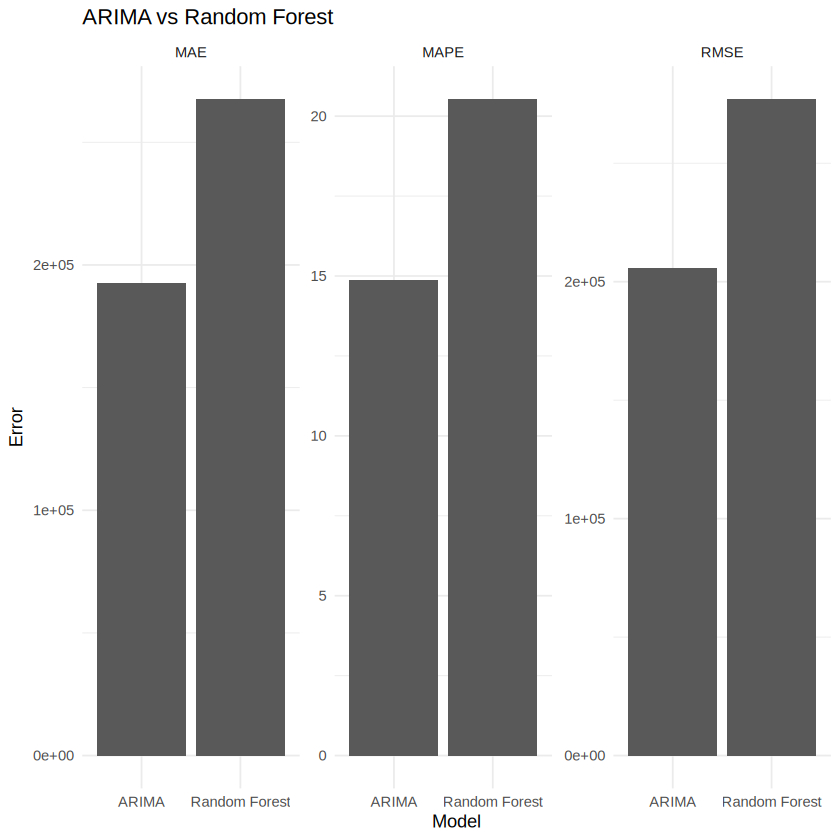

In [21]:
# ============================================================
# PLOT 6: MODEL COMPARISON
# ============================================================

comparison_long <- model_comparison %>%
  pivot_longer(
    cols = c(
      MAE,
      RMSE,
      MAPE
    ),
    names_to = "Metric",
    values_to = "Value"
  )

p6 <- ggplot(
  comparison_long,
  aes(
    x = Model,
    y = Value
  )
) +
  geom_col() +
  facet_wrap(
    ~Metric,
    scales = "free_y"
  ) +
  labs(
    title = "ARIMA vs Random Forest",
    x = "Model",
    y = "Error"
  ) +
  theme_minimal()

print(p6)

ggsave(
  "/content/EWaste_Case_Study/outputs/06_model_comparison.png",
  p6,
  width = 10,
  height = 6,
  dpi = 300
)

CELL 21 — Actual vs predicted values

In [22]:
# ============================================================
# ACTUAL VS PREDICTED
# ============================================================

prediction_comparison <- data.frame(
  Year = test_data$Year_Num,
  Actual = actual,
  ARIMA = arima_predictions,
  Random_Forest = rf_predictions
)

print(prediction_comparison)

write.csv(
  prediction_comparison,
  "/content/EWaste_Case_Study/outputs/prediction_comparison.csv",
  row.names = FALSE
)

  Year  Actual   ARIMA Random_Forest
1 2023 1254287 1518923       1593749
2 2024 1397956 1518923       1593749


CELL 22 — Actual vs predicted graph

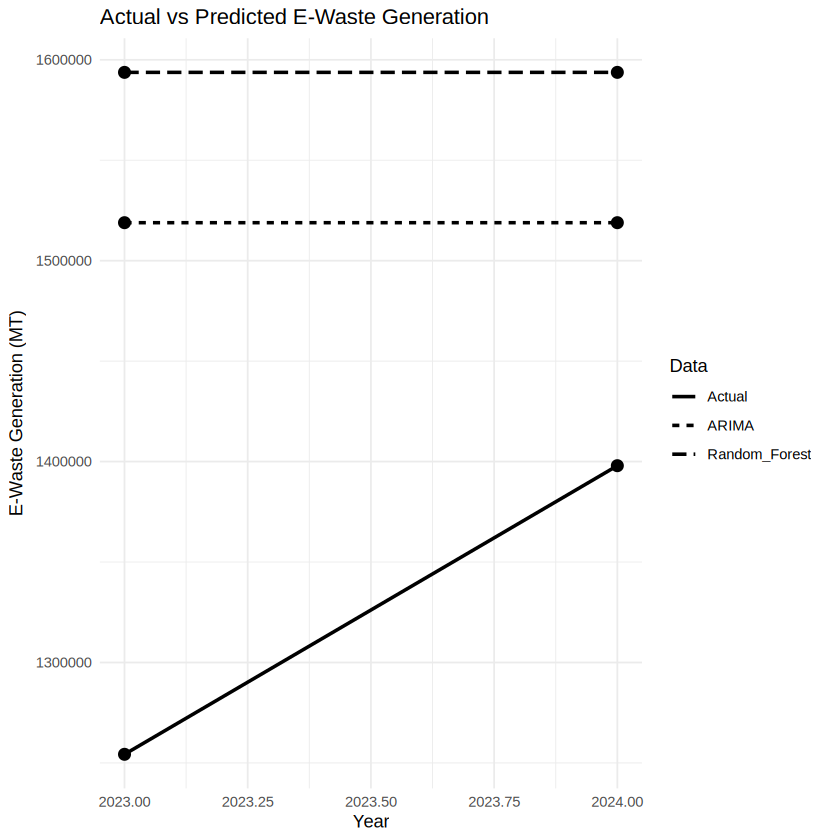

In [23]:
# ============================================================
# PLOT 7: ACTUAL VS PREDICTED
# ============================================================

prediction_long <- prediction_comparison %>%
  pivot_longer(
    cols = c(
      Actual,
      ARIMA,
      Random_Forest
    ),
    names_to = "Type",
    values_to = "Generated"
  )

p7 <- ggplot(
  prediction_long,
  aes(
    x = Year,
    y = Generated,
    group = Type,
    linetype = Type
  )
) +
  geom_line(linewidth = 1) +
  geom_point(size = 3) +
  labs(
    title = "Actual vs Predicted E-Waste Generation",
    x = "Year",
    y = "E-Waste Generation (MT)",
    linetype = "Data"
  ) +
  theme_minimal()

print(p7)

ggsave(
  "/content/EWaste_Case_Study/outputs/07_actual_vs_predicted.png",
  p7,
  width = 10,
  height = 6,
  dpi = 300
)

CELL 23 — Load additional e-waste dataset

In [24]:
# ============================================================
# ADDITIONAL E-WASTE DATASET
# ============================================================

additional_data <- read_csv(
  "/content/RS_Session_270_AS_140_A_i.csv",
  show_col_types = FALSE
)

print(names(additional_data))

print(additional_data)

[1] "Year"                                                        
[2] "E-Waste Generation (Metric Tonnes)"                          
[3] "Percentage increase of e-waste generation over previous year"
# A tibble: 3 × 3
  Year             `E-Waste Generation (Metric Tonnes)` Percentage increase of…¹
  <chr>                                           <dbl>                    <dbl>
1 2023-24                                      1254287.                    NA   
2 2024-25                                      1397956.                    11.4 
3 2025-26 (so far)                             1506710.                     7.78
# ℹ abbreviated name:
#   ¹​`Percentage increase of e-waste generation over previous year`


CELL 24 — Additional e-waste trend

In [25]:
# ============================================================
# ADDITIONAL E-WASTE TREND
# ============================================================

additional_clean <- additional_data

names(additional_clean)[1:3] <- c(
  "Year",
  "Generated",
  "Percentage_Increase"
)

additional_clean$Generated <- as.numeric(
  additional_clean$Generated
)

additional_clean$Percentage_Increase <- as.numeric(
  additional_clean$Percentage_Increase
)

print(additional_clean)

# A tibble: 3 × 3
  Year             Generated Percentage_Increase
  <chr>                <dbl>               <dbl>
1 2023-24           1254287.               NA   
2 2024-25           1397956.               11.4 
3 2025-26 (so far)  1506710.                7.78


CELL 25 — Additional dataset plot

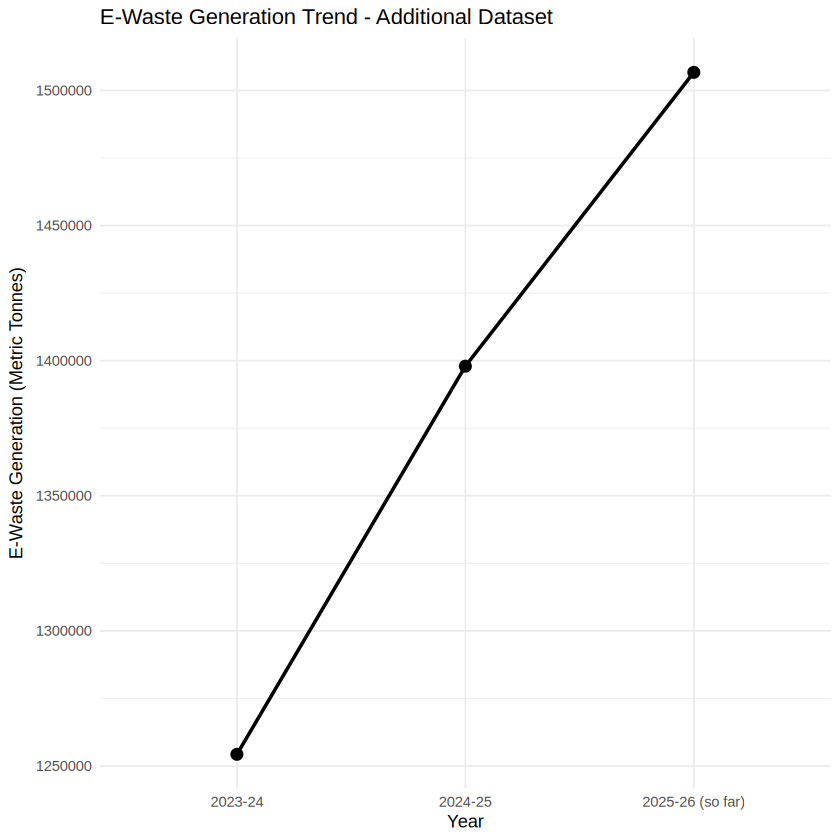

In [26]:
# ============================================================
# PLOT 8: ADDITIONAL E-WASTE TREND
# ============================================================

p8 <- ggplot(
  additional_clean,
  aes(
    x = Year,
    y = Generated,
    group = 1
  )
) +
  geom_line(linewidth = 1) +
  geom_point(size = 3) +
  labs(
    title = "E-Waste Generation Trend - Additional Dataset",
    x = "Year",
    y = "E-Waste Generation (Metric Tonnes)"
  ) +
  theme_minimal()

print(p8)

ggsave(
  "/content/EWaste_Case_Study/outputs/08_additional_ewaste_trend.png",
  p8,
  width = 9,
  height = 6,
  dpi = 300
)

CELL 26 — Load Census dataset

In [27]:
# ============================================================
# CENSUS DATA
# ============================================================

census_data <- read_excel(
  "/content/DDW_PCA2805_2011_MDDS with UI.xlsx",
  sheet = "EB-2805"
)

cat("\nCensus dimensions:\n")
print(dim(census_data))

cat("\nCensus columns:\n")
print(names(census_data))

cat("\nAdministrative levels:\n")
print(
  table(
    census_data$Level,
    useNA = "ifany"
  )
)


Census dimensions:
[1] 191  94

Census columns:
 [1] "State"          "District"       "Subdistt"       "Town/Village"  
 [5] "Ward"           "EB"             "Level"          "Name"          
 [9] "TRU"            "No_HH"          "TOT_P"          "TOT_M"         
[13] "TOT_F"          "P_06"           "M_06"           "F_06"          
[17] "P_SC"           "M_SC"           "F_SC"           "P_ST"          
[21] "M_ST"           "F_ST"           "P_LIT"          "M_LIT"         
[25] "F_LIT"          "P_ILL"          "M_ILL"          "F_ILL"         
[29] "TOT_WORK_P"     "TOT_WORK_M"     "TOT_WORK_F"     "MAINWORK_P"    
[33] "MAINWORK_M"     "MAINWORK_F"     "MAIN_CL_P"      "MAIN_CL_M"     
[37] "MAIN_CL_F"      "MAIN_AL_P"      "MAIN_AL_M"      "MAIN_AL_F"     
[41] "MAIN_HH_P"      "MAIN_HH_M"      "MAIN_HH_F"      "MAIN_OT_P"     
[45] "MAIN_OT_M"      "MAIN_OT_F"      "MARGWORK_P"     "MARGWORK_M"    
[49] "MARGWORK_F"     "MARG_CL_P"      "MARG_CL_M"      "MARG_CL_F"     
[5

CELL 27 — Extract ward-level data

In [28]:
# ============================================================
# WARD LEVEL DATA
# ============================================================

ward_data <- census_data %>%
  filter(
    Level == "WARD"
  ) %>%
  select(
    State,
    District,
    Subdistt,
    `Town/Village`,
    Ward,
    Name,
    No_HH,
    TOT_P,
    TOT_M,
    TOT_F
  )

cat("\nWard data dimensions:\n")

print(dim(ward_data))

cat("\nFirst rows:\n")

print(
  head(ward_data)
)


Ward data dimensions:
[1] 108  10

First rows:
# A tibble: 6 × 10
  State District Subdistt `Town/Village` Ward  Name      No_HH TOT_P TOT_M TOT_F
  <chr> <chr>    <chr>    <chr>          <chr> <chr>     <dbl> <dbl> <dbl> <dbl>
1 28    536      04496    802918         0104  GHMC (M …  7774 30701 15341 15360
2 28    536      04496    802918         0105  GHMC (M … 15740 69177 35124 34053
3 28    536      04496    802918         0107  GHMC (M … 13866 60103 31403 28700
4 28    536      04496    802918         0109  GHMC (M … 12367 51014 26031 24983
5 28    536      04496    802918         0110  GHMC (M …  8170 39937 20415 19522
6 28    536      04497    802918         0099  GHMC (M …  5459 20958 10508 10450


CELL 28 — Clean ward data

In [29]:
# ============================================================
# CLEAN WARD DATA
# ============================================================

ward_data <- ward_data %>%
  mutate(
    Population = as.numeric(TOT_P),
    Households = as.numeric(No_HH)
  ) %>%
  filter(
    !is.na(Population),
    !is.na(Households)
  )

# Check

summary(
  ward_data[
    c("Population", "Households")
  ]
)

print(
  head(ward_data)
)

   Population      Households   
 Min.   : 6762   Min.   :  627  
 1st Qu.:28674   1st Qu.: 6304  
 Median :34662   Median : 7388  
 Mean   :36512   Mean   : 7862  
 3rd Qu.:41904   3rd Qu.: 9017  
 Max.   :69177   Max.   :15740  

# A tibble: 6 × 12
  State District Subdistt `Town/Village` Ward  Name      No_HH TOT_P TOT_M TOT_F
  <chr> <chr>    <chr>    <chr>          <chr> <chr>     <dbl> <dbl> <dbl> <dbl>
1 28    536      04496    802918         0104  GHMC (M …  7774 30701 15341 15360
2 28    536      04496    802918         0105  GHMC (M … 15740 69177 35124 34053
3 28    536      04496    802918         0107  GHMC (M … 13866 60103 31403 28700
4 28    536      04496    802918         0109  GHMC (M … 12367 51014 26031 24983
5 28    536      04496    802918         0110  GHMC (M …  8170 39937 20415 19522
6 28    536      04497    802918         0099  GHMC (M …  5459 20958 10508 10450
# ℹ 2 more variables: Population <dbl>, Households <dbl>


CELL 29 — Ward population analysis

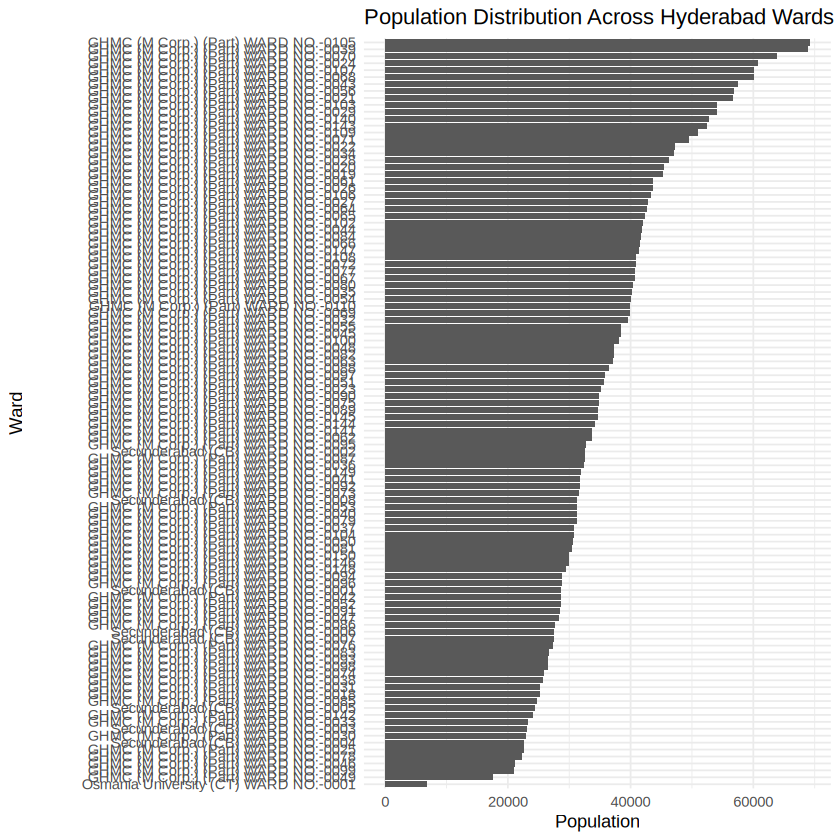

In [30]:
# ============================================================
# WARD POPULATION ANALYSIS
# ============================================================

p9 <- ggplot(
  ward_data,
  aes(
    x = reorder(
      Name,
      Population
    ),
    y = Population
  )
) +
  geom_col() +
  coord_flip() +
  labs(
    title = "Population Distribution Across Hyderabad Wards",
    x = "Ward",
    y = "Population"
  ) +
  theme_minimal()

print(p9)

ggsave(
  "/content/EWaste_Case_Study/outputs/09_ward_population.png",
  p9,
  width = 10,
  height = 8,
  dpi = 300
)

CELL 30 — K-Means clustering

In [31]:
# ============================================================
# K-MEANS ZONE OPTIMIZATION
# ============================================================

# Select variables used for clustering

zone_features <- ward_data %>%
  select(
    Population,
    Households
  )

# Standardize variables

zone_scaled <- scale(
  zone_features
)

# Reproducibility

set.seed(123)

# K = 3 zones

kmeans_model <- kmeans(
  zone_scaled,
  centers = 3,
  nstart = 25
)

# Add cluster labels

ward_data$Zone <- factor(
  kmeans_model$cluster,
  labels = c(
    "Zone 1",
    "Zone 2",
    "Zone 3"
  )
)

# Display result

print(
  ward_data %>%
    select(
      Name,
      Population,
      Households,
      Zone
    )
)

# A tibble: 108 × 4
   Name                                Population Households Zone  
   <chr>                                    <dbl>      <dbl> <fct> 
 1 GHMC (M Corp.) (Part) WARD NO.-0104      30701       7774 Zone 1
 2 GHMC (M Corp.) (Part) WARD NO.-0105      69177      15740 Zone 3
 3 GHMC (M Corp.) (Part) WARD NO.-0107      60103      13866 Zone 3
 4 GHMC (M Corp.) (Part) WARD NO.-0109      51014      12367 Zone 3
 5 GHMC (M Corp.) (Part) WARD NO.-0110      39937       8170 Zone 1
 6 GHMC (M Corp.) (Part) WARD NO.-0099      20958       5459 Zone 2
 7 GHMC (M Corp.) (Part) WARD NO.-0100      38112       9363 Zone 1
 8 GHMC (M Corp.) (Part) WARD NO.-0145      34659       8240 Zone 1
 9 GHMC (M Corp.) (Part) WARD NO.-0146      29920       6909 Zone 2
10 GHMC (M Corp.) (Part) WARD NO.-0147      41336       9489 Zone 1
# ℹ 98 more rows


CELL 31 — Zone summary

In [32]:
# ============================================================
# ZONE SUMMARY
# ============================================================

cluster_summary <- ward_data %>%
  group_by(Zone) %>%
  summarise(
    Wards = n(),
    Population = sum(
      Population,
      na.rm = TRUE
    ),
    Households = sum(
      Households,
      na.rm = TRUE
    ),
    Avg_Population = mean(
      Population,
      na.rm = TRUE
    ),
    Avg_Households = mean(
      Households,
      na.rm = TRUE
    )
  ) %>%
  arrange(Zone)

print(cluster_summary)

write.csv(
  cluster_summary,
  "/content/EWaste_Case_Study/outputs/zone_summary.csv",
  row.names = FALSE
)

# A tibble: 3 × 6
  Zone   Wards Population Households Avg_Population Avg_Households
  <fct>  <int>      <dbl>      <dbl>          <dbl>          <dbl>
1 Zone 1    49    1922256     414164        1922256         414164
2 Zone 2    45    1202798     262991        1202798         262991
3 Zone 3    14     818269     171896         818269         171896


CELL 32 — Zone visualization

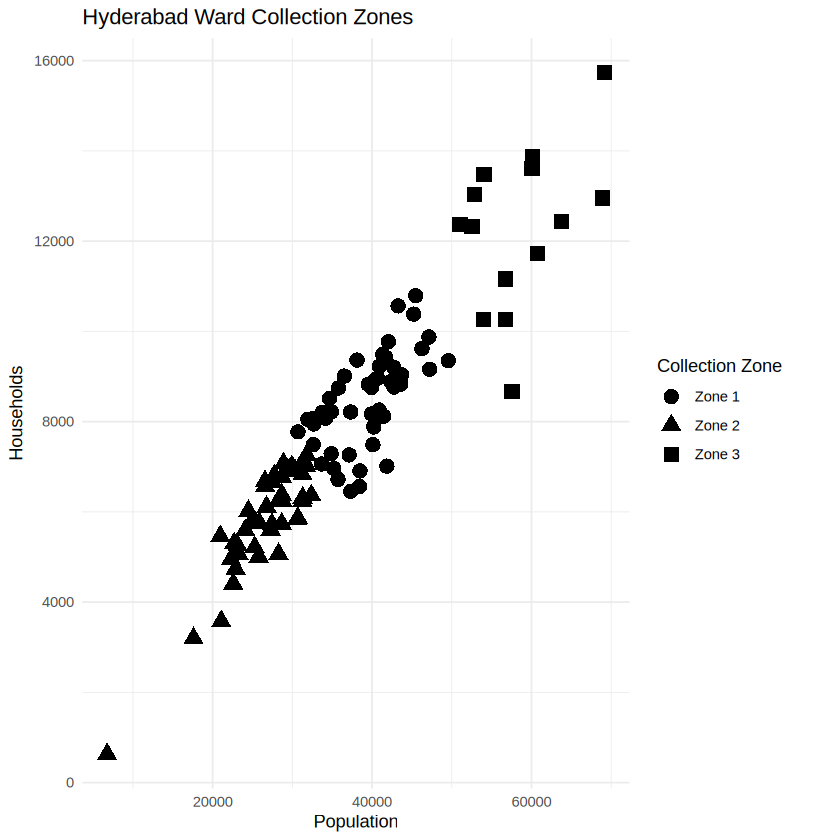

In [33]:
# ============================================================
# PLOT 10: COLLECTION ZONES
# ============================================================

p10 <- ggplot(
  ward_data,
  aes(
    x = Population,
    y = Households,
    shape = Zone
  )
) +
  geom_point(size = 4) +
  labs(
    title = "Hyderabad Ward Collection Zones",
    x = "Population",
    y = "Households",
    shape = "Collection Zone"
  ) +
  theme_minimal()

print(p10)

ggsave(
  "/content/EWaste_Case_Study/outputs/10_collection_zones.png",
  p10,
  width = 9,
  height = 6,
  dpi = 300
)

CELL 33 — Zone population graph

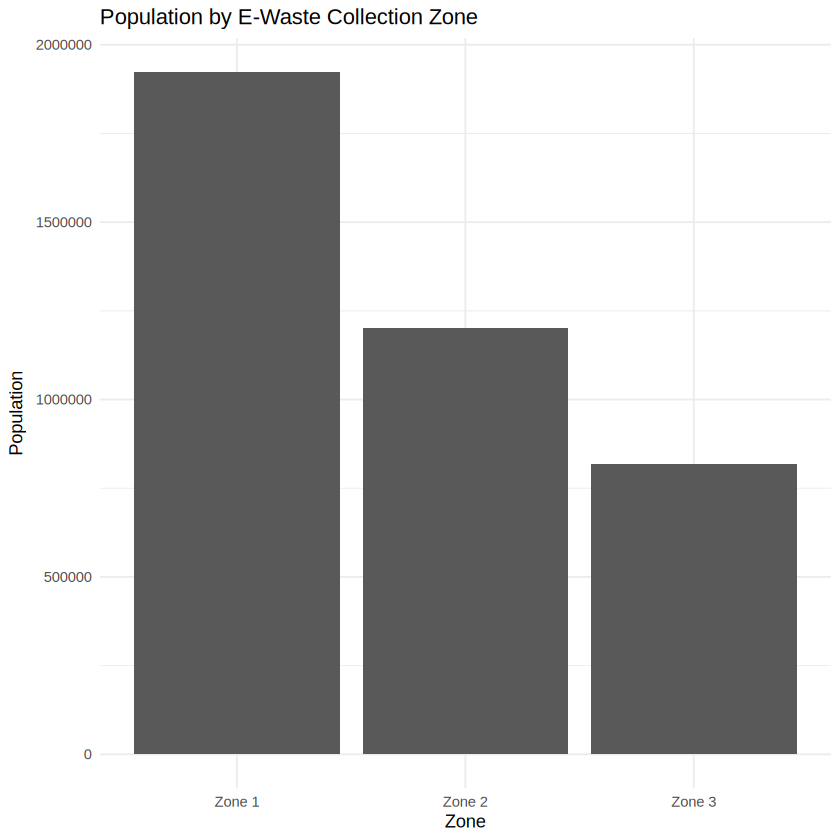

In [34]:
# ============================================================
# PLOT 11: ZONE POPULATION
# ============================================================

p11 <- ggplot(
  cluster_summary,
  aes(
    x = Zone,
    y = Population
  )
) +
  geom_col() +
  labs(
    title = "Population by E-Waste Collection Zone",
    x = "Zone",
    y = "Population"
  ) +
  theme_minimal()

print(p11)

ggsave(
  "/content/EWaste_Case_Study/outputs/11_zone_population.png",
  p11,
  width = 8,
  height = 6,
  dpi = 300
)

CELL 34 — Zone households graph

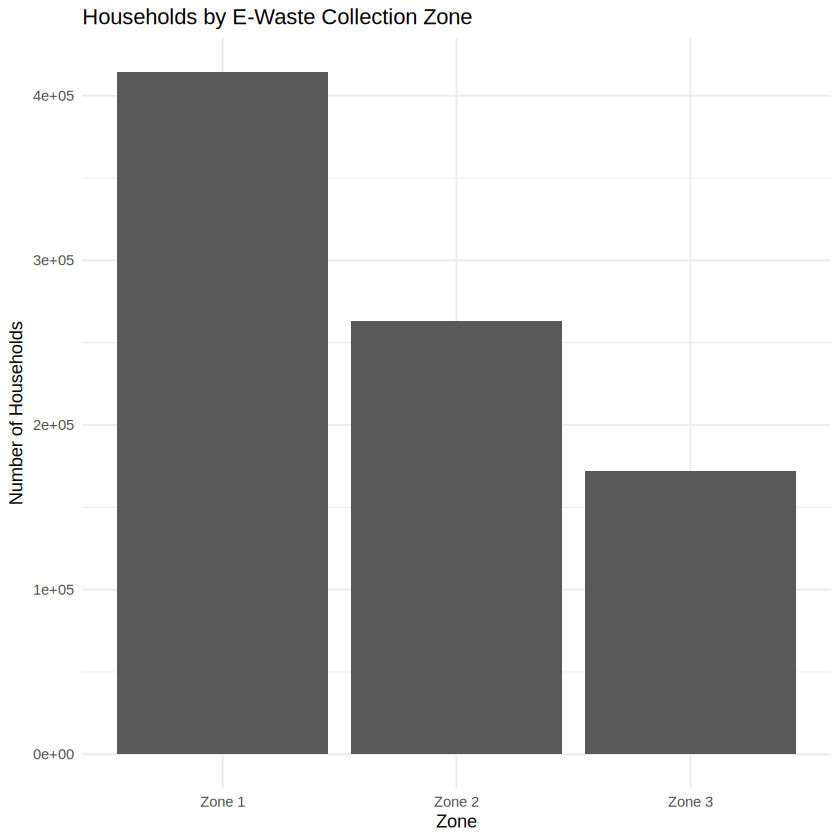

In [35]:
# ============================================================
# PLOT 12: HOUSEHOLDS BY ZONE
# ============================================================

p12 <- ggplot(
  cluster_summary,
  aes(
    x = Zone,
    y = Households
  )
) +
  geom_col() +
  labs(
    title = "Households by E-Waste Collection Zone",
    x = "Zone",
    y = "Number of Households"
  ) +
  theme_minimal()

print(p12)

ggsave(
  "/content/EWaste_Case_Study/outputs/12_zone_households.png",
  p12,
  width = 8,
  height = 6,
  dpi = 300
)

CELL 35 — Final results

In [36]:
# ============================================================
# FINAL PROJECT RESULTS
# ============================================================

cat("\n")
cat("====================================================\n")
cat(" E-WASTE COLLECTION DEMAND FORECASTING\n")
cat(" AND ZONE OPTIMIZATION USING R\n")
cat("====================================================\n")

cat("\n1. DATASET SUMMARY\n")
cat("----------------------------\n")
cat(
  "Historical observations:",
  nrow(ewaste_clean),
  "\n"
)

cat(
  "Ward observations:",
  nrow(ward_data),
  "\n"
)

cat("\n2. ARIMA PERFORMANCE\n")
cat("----------------------------\n")
cat(
  "MAE  :",
  arima_mae,
  "\n"
)

cat(
  "RMSE :",
  arima_rmse,
  "\n"
)

cat(
  "MAPE :",
  arima_mape,
  "%\n"
)

cat("\n3. RANDOM FOREST PERFORMANCE\n")
cat("----------------------------\n")

cat(
  "MAE  :",
  rf_mae,
  "\n"
)

cat(
  "RMSE :",
  rf_rmse,
  "\n"
)

cat(
  "MAPE :",
  rf_mape,
  "%\n"
)

cat("\n4. BEST MODEL\n")
cat("----------------------------\n")

if (arima_rmse < rf_rmse) {
  cat(
    "ARIMA performed better based on RMSE.\n"
  )
} else {
  cat(
    "Random Forest performed better based on RMSE.\n"
  )
}

cat("\n5. COLLECTION ZONES\n")
cat("----------------------------\n")

print(cluster_summary)

cat("\n====================================================\n")
cat(" PROJECT EXECUTION COMPLETED\n")
cat("====================================================\n")


 E-WASTE COLLECTION DEMAND FORECASTING
 AND ZONE OPTIMIZATION USING R

1. DATASET SUMMARY
----------------------------
Historical observations: 5 
Ward observations: 108 

2. ARIMA PERFORMANCE
----------------------------
MAE  : 192801.8 
RMSE : 205749.2 
MAPE : 14.87586 %

3. RANDOM FOREST PERFORMANCE
----------------------------
MAE  : 267627.4 
RMSE : 277100.4 
MAPE : 20.5349 %

4. BEST MODEL
----------------------------
ARIMA performed better based on RMSE.

5. COLLECTION ZONES
----------------------------
# A tibble: 3 × 6
  Zone   Wards Population Households Avg_Population Avg_Households
  <fct>  <int>      <dbl>      <dbl>          <dbl>          <dbl>
1 Zone 1    49    1922256     414164        1922256         414164
2 Zone 2    45    1202798     262991        1202798         262991
3 Zone 3    14     818269     171896         818269         171896

 PROJECT EXECUTION COMPLETED
